In [ ]:
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning
from data import load_data

X_train, y_train, X_val, y_val, X_test, y_test = load_data()
print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)
print("pixel range:", X_train.min(), "to", X_train.max(), "(NMF needs no negatives - good)")

train: (54000, 784)  val: (6000, 784)  test: (10000, 784)
pixel range: 0.0 to 1.0 (NMF needs no negatives - good)


In [4]:
# test to pick max_tiers and d values for NMF

rng = np.random.default_rng(0)
X_small = X_train[rng.choice(len(X_train), 5000, replace=False)]

def try_nmf(X, d, max_iter):
    model = NMF(n_components=d, init="nndsvda", random_state=0, max_iter=max_iter)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        start = time.perf_counter()
        model.fit(X)
        fit_time = time.perf_counter() - start
    converged = not any(issubclass(x.category, ConvergenceWarning) for x in w)
    return model, fit_time, converged

for d in [32, 128]:
    for max_iter in [200, 500, 1000]:
        model, t, ok = try_nmf(X_small, d, max_iter)
        print(f"d={d:4d}  max_iter={max_iter:5d} | used {model.n_iter_:4d} iters | "
              f"error {model.reconstruction_err_:8.2f} | {t:6.1f}s | converged={ok}")

d=  32  max_iter=  200 | used  200 iters | error   263.52 |    0.7s | converged=False
d=  32  max_iter=  500 | used  500 iters | error   262.99 |    1.8s | converged=False
d=  32  max_iter= 1000 | used  655 iters | error   262.95 |    2.3s | converged=True
d= 128  max_iter=  200 | used  200 iters | error   180.51 |    7.0s | converged=False
d= 128  max_iter=  500 | used  500 iters | error   178.91 |   17.0s | converged=False
d= 128  max_iter= 1000 | used 1000 iters | error   178.46 |   33.5s | converged=False


The output above suggests max_iter = 1000. At d = 32, NMF converges in 655 iterations. At d = 128, it still shows a convergence warning, but the error improves by less than 0.3% from 500 to 1000 iterations, so more iterations would add time with almost no benefit.

In [5]:
MAX_ITER = 1000

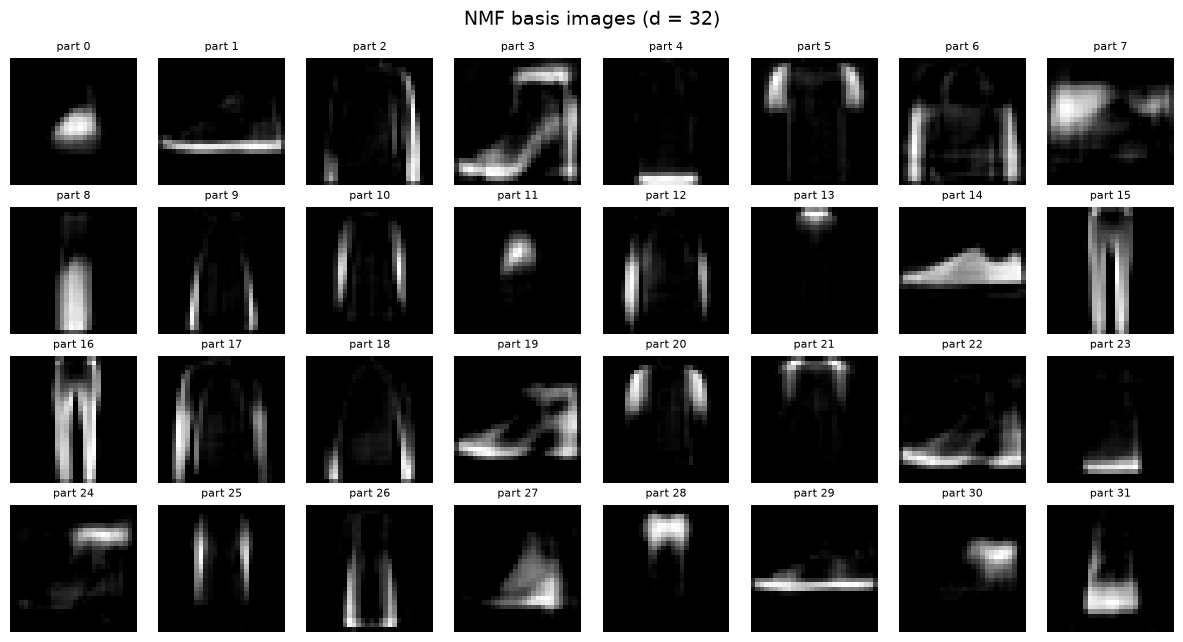

In [10]:
def plot_basis(model, filename=None):
    fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
    for i, ax in enumerate(axes.flat):
        ax.imshow(model.components_[i].reshape(28, 28), cmap="gray")
        ax.set_title(f"part {i}", fontsize=8)
        ax.axis("off")
    plt.suptitle("NMF basis images (d = 32)", fontsize=14)
    plt.tight_layout()
    if filename:                      # only saves if you give it a name
        plt.savefig(filename, dpi=150)
    plt.show()

model32, fit32, ok32 = try_nmf(X_small, 32, MAX_ITER)
plot_basis(model32)                   # just shows it, no file saved

Encoding 1,000 images took 0.02s  (0.02 ms per image)
MSE on these 1,000 images: 0.0172


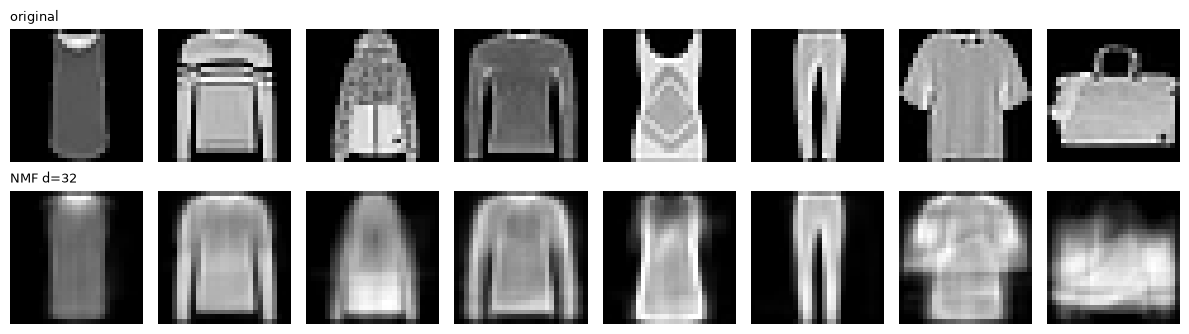

In [ ]:
# encode time and reconstruction check on a batch of 1,000 validation images

batch = X_val[:1000]
start = time.perf_counter()
Z = model32.transform(batch)          # compressed features: 1000 x 32
enc_time = time.perf_counter() - start
print(f"Encoding 1,000 images took {enc_time:.2f}s  ({enc_time:.2f} ms per image)")

recon = np.clip(model32.inverse_transform(Z), 0, 1)
print(f"MSE on these 1,000 images: {np.mean((batch - recon) ** 2):.4f}")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axes[0, i].imshow(batch[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(recon[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=9)
axes[1, 0].set_title("NMF d=32", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# Extra check for dipped in scaling

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize

for d in [16, 32, 64, 128]:
    z = np.load(f"latents/NMF_d{d}_s0.npz")
    Ztr, Zte = z["Z_train"], z["Z_test"]
    raw = KNeighborsClassifier(n_neighbors=9, n_jobs=-1).fit(Ztr, y_train).score(Zte, y_test)
    nrm = KNeighborsClassifier(n_neighbors=9, n_jobs=-1).fit(normalize(Ztr), y_train).score(normalize(Zte), y_test)
    print(f"d={d:4d} | official {raw:.4f} | normalized {nrm:.4f}")

d=  16 | official 0.7798 | normalized 0.7800
d=  32 | official 0.7829 | normalized 0.7830
d=  64 | official 0.7579 | normalized 0.7613
d= 128 | official 0.7543 | normalized 0.7630


**Observation:** 
From the extra check above, normalizing changed accuracy by less than 1 point (d = 128: 0.754 → 0.763), and the peak stays at d = 32. The dip is a property of NMF's parts-based features, not a scaling issue. The results are unchanged; this check is for interpretation only.